# Introduction to Fourier Methods: Exercises

James Johnson, CIERA/Northwestern

LSST Discovery Alliance Data Science Fellowship Program

Session 27: Time-Series Analysis

November 16-20, 2026

Caltech/IPAC, Pasadena, CA

## Problem 1: Implement A Fourier Series

In the lecture, we saw that any infinitely periodic function can be represented by an infinite series of sine and cosine functions. We saw the square wave as an example, with approximations up to a few different choices of where the summation was cut off. Pick another periodic function, compute its Fourier series, and implement a numerical approximation of the first $n$ terms. Plot the approximation on top of the original waveform to check your solution.

You may choose any waveform you'd like, but the solutions implement the sawtooth wave:

$$
f(x) = x \% 1
$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np

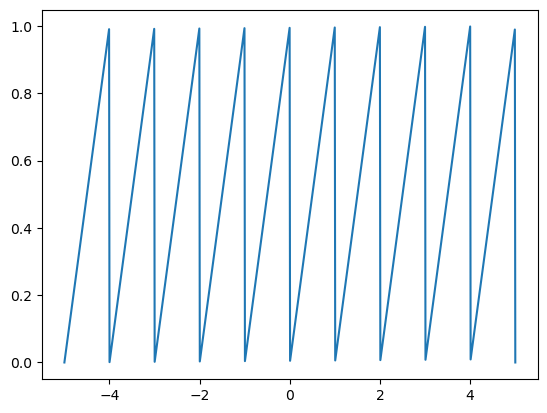

In [12]:
def sawtooth_wave(x):
    r"""
    The sawtooth wave as a function of an arbitrary x-coordinate.
    """
    return x % 1

xvals = np.linspace(-5, 5, 1000)
yvals = [sawtooth_wave(x) for x in xvals]
plt.plot(xvals, yvals)

**Consider documenting your analytic solution in LaTeX here**


# Review: Fourier's Theorem

**Any periodic signal can be represented as a series of sines and cosines.**

Any function $f(x)$ with a period $T$ can be written as:

$$
\begin{align}
f(x) &= A_0 + \sum_{n=1}^\infty \left[
A_n \cos \left( \frac{2n\pi x}{T} \right) + B_n \sin \left(\frac{2n\pi x}{T} \right)
\right]
\\
A_0 &= \frac{1}{T} \int_0^T f(x) dx
\\
A_n &= \frac{2}{T} \int_0^T f(x) \cos \left(\frac{2n\pi x}{T}\right) dx
\\
B_n &= \frac{2}{T} \int_0^T f(x) \sin \left(\frac{2n\pi x}{T}\right) dx
\end{align}
$$

$$
\begin{align}
f(x) &= A_0 + \sum_{n=1}^\infty \left[
A_n \cos \left( \frac{2n\pi x}{T} \right) + B_n \sin \left(\frac{2n\pi x}{T} \right)
\right]
\\
A_0 &= \frac{1}{T} \int_0^T x dx, \;T = 1
\\
\int_0^1 x dx &= \left. \frac{1}{2}x^2 \right|_{0}^{1} = \frac{1}{2}x^2 - \frac{1}{2}0^2 = \frac{1}{2}
\\
A_n &= \frac{2}{T} \int_0^T f(x) \cos \left(\frac{2n\pi x}{T}\right) dx \text{-> this function is odd so, } A_n = 0
\\
B_n &= \frac{2}{T} \int_0^T f(x) \sin \left(\frac{2n\pi x}{T}\right) dx
\\
2 \int_0^T x \sin \left(\frac{2n\pi x}{T}\right) dx &= \frac{-1}{\pi n}
\\
f(x) &= \frac{1}{2} - \frac{1}{\pi}\sum_{n=1}^{\infty}\left[\frac{\sin \left(2n\pi x\right)}{n}\right]
\end{align}
$$

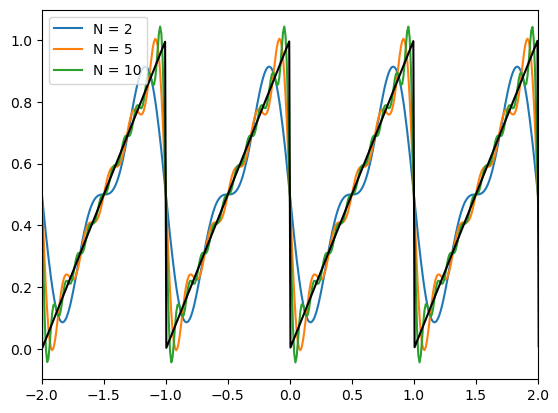

In [13]:
def sawtooth_wave_fourier(x, n = 10): # complete
    if n:
        return -1 / np.pi * np.sin(2 * np.pi * n * x) / n + sawtooth_wave_fourier(x, n = n - 1)
    else:
        return 1 / 2

for n in [2, 5, 10]:
    yvals = [sawtooth_wave_fourier(x, n = n) for x in xvals]
    plt.plot(xvals, yvals, label = r"N = %d" % (n))
plt.plot(xvals, [sawtooth_wave(x) for x in xvals], c = 'k')
plt.xlim([-2, 2])
plt.legend()

## Problem 2: Fourier Pairs

In the lecture, we saw that there are families of functions that are Fourier transform "pairs" of one another. For example, the Fourier transform of a single sinusoid is two delta functions at the positive and negative values of the frequency of the input wave. Conversely, the single sinusoid is the inverse Fourier transform of those two delta functions.

As astronomers, there are other "pairs" of function families that are Fourier transform pairs of one another, and it is useful to be aware of these pairs on a conceptual level.

In this problem, we'll explore a couple of them. No need to compute them by hand -- let's switch to using publicly available tools that you're much more likely to be familiar with through research (or perhaps already are!). Feel free to use routines like `numpy.fft.fft` or `scipy.fft.fft` as you are comfortable. The solutions will use `scipy.fft.fft`, but as we saw in lecture, there are many conventions for implementing Fourier transforms, and what's important is not that you use a specific one, but rather that you remain consistent throughout a given set of related calculations. In the solutions, I'll be using the `SciPy` implementation, and the we'll want the following functions from `scipy.fft`:

In [14]:
from scipy.fft import fft, ifft, fftfreq, fftshift, ifftshift

The functions `fft` and `ifft` compute dimensionless discrete Fourier transforms and their inverses, while `fftfreq` separately computes the frequencies associated with `fft`. `fftshift` and `ifftshift` are useful to shifting the order of the frequencies back and forth for plotting versus computing the transforms.

If you're unfamiliar with computing FFTs in SciPy, it's helpful to "test out" the `fftshift` and `ifftshift` functions by printing their outputs. For reasons relating to the shift theorem, wrapping these two functions around FFTs completely prevents factors of $(-1)^k$ arising, which presents visually as alternating sign flips between bins in the frequency domain.

### Problem 2a

What is the Fourier transform of a Gaussian distribution? Start by defining the functional form for a Gaussian according to

$$
\mathcal{N}(x) = A e^{-(x - \mu)^2 / 2\sigma^2},
$$

where $A$ is a constant of normalization, $\mu$ is the mean of the distribution, and $\sigma$ is the standard deviation.

In [15]:
def gaussian(x, A = 1, mu = 0, sigma = 1):
    return A * np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))

Now let's take the Fourier transform of this Gaussian. Map this function across a dense grid of x-coordinate values and plot it up.

<!-- Let's transition to computing Fourier transforms numerically using publicly available tools that you will likely want to use if Fourier methods are relevant to your research. `SciPy` provides a number of useful routines as part of `scipy.fft`. The function `scipy.fft.fft` computes dimensionless a Fast Fourier Transform, like the one shown in the lecture. `scipy.fft.fftfreq` returns the frequencies associated with `scipy.fft.fft`. Lastly, `scipy.fft.ifft` computes the inverse Fourier transform.

TODO: Remind of shift theorem and how factors of $(-1)^k$ can get introduced. Introduce `fftshift` and `ifftshift` as ways to handle this.

As your next step, import these functions from `SciPy`, compute the Gaussian distribution on a dense array of x-coordinates, and compute its Fourier transform. You'll need one call each to `fft` and one to `fftfreq`, both of which should be short and simple lines of code. -->

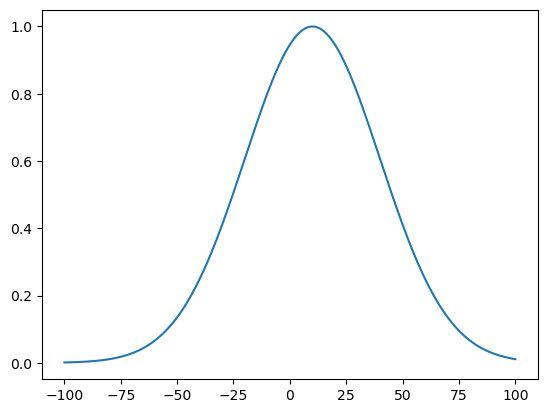

In [33]:
x = np.arange(-100, 100, 0.01)
plt.plot(x, gaussian(x, mu=10, sigma=30))

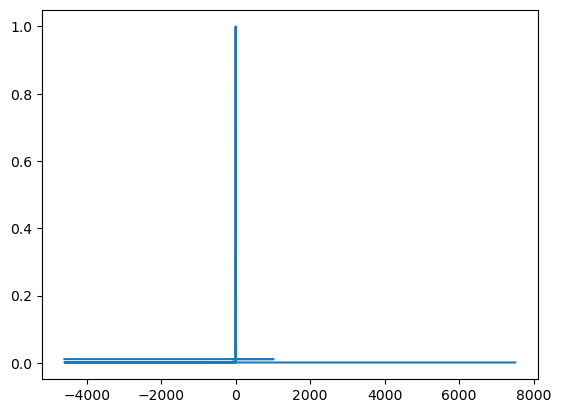

In [34]:
y = gaussian(x, mu=10, sigma=30)
x_fft = fft(y)
plt.plot(x_fft, y)

What is the shape of this function, which is the Fourier transform of a Gaussian?

Now let's look at some variations of this Gaussian. Choose a different amplitude, a different mean, and a different standard deviation to try out. Plot each them in the time domain and the frequency domain side-by-side to see how the parameters influence the Fourier transform.

In [ ]:
fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(121) # for the time-domain
ax2 = fig.add_subplot(122) # for the frequency-domain

# complete

How do the properties of the input Gaussian relate to the properties of its Fourier transform? How does a single change in the amplitude, mean, or standard deviation influence its Fourier transform? Can you make sense of these results by relating them to the stretch theorem and shift theorem?

### Problem 2b

Repeat Problem 1a for a top-hat function:

$$
f(x) = \begin{cases}
1 & (\left|x\right| \leq 1)
\\
0 & (\left|x\right| > 1).
\end{cases}
$$

With the same procedure, discover the shape of the Fourier transform of a top-hat function for yourself. Determine how the output changes based on isolated changes to the width of the top-hat as well as its height, and make sense of these relationships using the stretch and shift theorems.

**Hint**: Instead of plotting the absolute value of this Fourier transform, switch to just grabbing the real component (i.e., something like `ft = [_.real for _ in ft]` before plotting as opposed to `abs` or `np.abs`).

In [ ]:
def tophat(x, width = 1, height = 1): # complete -- soln:

In [ ]:
fig = plt.figure(figsize = (10, 5))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

# complete -- soln:

What is the name of this family of functions? In general, you should expect this kind of "damped wave" type of output when taking Fourier transforms of functions with sharp boundaries, like the top-hat function. This is the same reason why the approximation for the square wave becomes numerically unstable very near the transitions between $f(x) = +1$ and $-1$.

# Problem 3

Charlie Brown was out camping and stargazing with his telescope one night, when he and Snoopy noticed that one particular star seemed to be dimming and re-brightening every few days. They were kind enough to record the brightness of the star (in magnitudes, of course) at midnight *every* night for a whole year, with a precision of $\sigma_m = 0.01$.

The file is right here in this directory, named "SnoopysLightCurve.dat." The first column is the index of the night of observations, and the second is the magnitudes that they recorded each night. Load in their data and plot the magnitude versus the day.

In [ ]:
data = np.genfromtxt("SnoopysLightCurve.dat")
days = data[:, 0]
mags = data[:, 1]

plt.errorbar(days, mags, yerr = 0.01, linestyle = "None")

This star really is going all over the place! Let's see if we can help Chuck and Snoopy figure out what kind of star they found. Using Fourier methods, determine the period for this star and phase-fold the lightcurve. Start by plotting the Fourier transform of their data. It might help to use a log-scaled y-axis.

In [ ]:
# complete

We should see a few oscillation modes, but which one is the "primary" mode of oscillation? It's probably not the one near $k = 0$, since our real data definitely do not show a low frequency. The next highest peak is around $k \approx \pm 0.3$.

Isolate the value of the peak near $k \approx +0.3$. Find the values of the two frequencies defining its bin edges. Those two bin edges correspond to two specific period values. If this peak in our frequency spectrum is the "primary" peak, then the period we're looking for should be between those two bin edges. Pick one of the two values to start with and phase-fold the light-curve. Iteratively update the period within this frequency bin of peak power until you see the data "tighten." You should see a clear trend once you've identified the right period.

In [ ]:
# complete

What is the period of Chuck and Snoopy's newly discovered variable star? Can you tell what kind of variable star this is? Or rather, what kind of variable star I took inspiration from when generating fake data?

# Problem 4: A Simple High-Pass Filter

In this problem, we'll examine how to remove a long-term modulation from some signal. Some telescopes and instruments are known to "drift" due to imperfections in their design. The Kepler spacecraft became a famous example of this effect after multiple components in its positioning system broke, requiring scientists to take extra steps to analyze Kepler data (more specifically K2 data).

This exercise is not intended to mimic the kind of detrending that one does to analyze Kepler/K2 data specifically, but it should nonetheless give you a sense of how filtering can be useful for these purposes.

Let's start with our "not-so-simple-sinusoid" from lecture and add some long-period modulation to it. Let's do so at an amplitude that is comparable to the input wave itself, so that both the input waveform and the modulation are clear by eye. For this exercise, we'll "observe" our signal for longer than we did in lecture: 25 days this time, but still 500 observations per day.

In [ ]:
def not_so_simple_sinusoid(t):
    r"""
    A three-component sinusoid that this notebook uses as a baseline example 
    periodic function.

    Parameters
    ----------
    t : `float`
        Time :math:`t`, in arbitrary units (discussion assumes days).

    Returns
    -------
    The value of an arbitrary "signal" observed at the specified time.
    """
    return np.sin(2 * np.pi * t) + 0.5 * np.sin(7.2 * np.pi * t) + 0.2 * np.sin(29.8 * np.pi * t)

def slow_drift(t):
    r"""
    A low-frequency "signal drift" on top of our "not-so-simple-sinusoid" from lecture.
    """
    return 1.2 * np.sin(0.1 * np.pi * t)

times = np.linspace(0, 25, 25 * 500)
signal = [not_so_simple_sinusoid(t) + slow_drift(t) for t in times]

plt.plot(times, signal)
plt.xlabel(r"Time [days]")
plt.ylabel(r"Signal")
plt.show()

Plot the Fourier transform of this signal. Zoom in near a frequency of zero to see the individual oscillation modes.

In [ ]:
# complete

You should see the three pairs of peaks near $k \approx \pm 1$ day$^{-1}$, $k \approx \pm 3$ day$^{-1}$, and $k \approx \pm 15$ day$^{-1}$, but with an additional, slightly broader peak near $k \approx 0$.

Apply a simple filter that removes the low-frequency oscillations. Choose some threshold frequency below which you set the Fourier transform to zero, but above which you do nothing. Plot the new Fourier series.

In [ ]:
# complete

Move this modified signal back to the time domain by taking its inverse Fourier transform. Plot the recovered signal alongside the original, input modified signal and the same "not-so-simple-sinusoid" without the long-period modulation. You might want to zoom in on the first $\sim$few days of the signal for visual clarity.

In [ ]:
# complete

Has your low-frequency filter successfully recovered a similar waveform as the "not-so-simple-sinusoid?" If there are large discrepancies, return to your low-frequency filter, choose a new threshold, and rerun the last few cells. Iterate through these steps a few times until you successfully recover the original waveform. Where does your reconstructed version differ from the original?

What you have just done is basically a crude form of "high-pass" filtering. In lecture, the example we saw would be described as "low-pass" filtering. The two differ simply in what frequency ranges they seek to remove: a *low-pass* filter removes high frequencies (i.e., low frequencies pass), while a *high-pass* filter removes low frequencies (i.e., high frequencies pass).

## Problem 4: Removing Noise

I added some noise to the "not-so-simple-sinusoid." The array of the times and the noisy signal can be found in "NoisySinusoid.dat" in this directory. Read in the file and de-noise the signal with frequency filtering. Compare your result with both the noisy and un-noisy version of the not-so-simple-sinusoid.

In [ ]:
# complete

## Problem 5: A Deeper Understanding of Leakage

Up until now, we've only inspected Fourier transforms with significant leakage. Let's construct an example where we eliminate leakage all the way down to floating point precision to *really* understand what's going on.

For this exercise, it helps to first choose a set of frequencies that you'll sample some waveform at, as opposed to setting a waveform and sampling it. By choosing a number of sample and a sampling interval that are both powers of ten, we can identify a frequency that is a nice round number:

In [ ]:
N = 1000
d = 0.01
freqs = fftshift(fftfreq(N, d = d))
print(fftshift(freqs))

With $N = 1000$ samples each $\Delta t = 0.01$ units apart, we will sample frequencies at intervals of $\Delta k = 0.1$, in whatever time and frequency units we choose to interpret these numbers in.

Choose a frequency whose exact value is in this list; I'll use $k = 3$. Pair this with a frequency that is *ever so slightly* different; I'll use $k = 3.01$. The idea is to pick a value that is *exactly* at one of the sampled frequency values and one that is *between* two of them.

Plot the two sinusoids and their Fourier transforms side-by-side.

In [ ]:
# complete

What do you notice about the Fourier spectrum of the $k = 3$ versus $k = 3.01$ single sinusoids?

This is one of the key principles behind leakage. In order for an oscillation mode to *truly* show up as a delta function in a discrete Fourier transform, the signal needs to be sampled at *exactly* that frequency. If the sampling rate is such a given frequency component sits *between* two frequency bins, it does *not* produce signal in its two adjacent bins. It produces leakage at *every* frequency.

# Problem 6

Now we'll compute the Fourier transform of a real Kepler light curve.

First we'll install the package `lightkurve`. We'll use this package to download and plot light curves, but it has a lot of useful functions for working with them as well. 

In [ ]:
%pip install lightkurve

In [ ]:
from lightkurve import search_targetpixelfile
import lightkurve as lk

We'll download the data for a specific star:

In [ ]:
#Download KIC 3541346 lightcurve (flux VS time):
search_result = lk.search_lightcurve('KIC 3541346', author='Kepler', cadence='long')
print(search_result)

Downloading the data:

In [ ]:
lc_collection = search_result.download_all()
#we stitch all the quarters together:
lc_stitched = lc_collection.stitch()
lc_stitched.plot()

In order for a Fourier transform to work properly, we need our data to be evenly sampled in time. We'll most likely to clean this sample a little, since real data are most often not measured perfectly periodically.

In [ ]:

# Let's start by seeing where the largest gaps are
time = lc_stitched.time.to_value(format='jd')
flux = lc_stitched.flux.to_value()

plt.figure()
plt.plot(np.diff(time), color='dodgerblue')

print(np.median(np.diff(time)))
print(np.diff(time))

The median time difference between measurements is $\sim$$0.02$ with little variation, but there appear to be some breaks in the data, where chunks of time are reported out-of-order (hence the negative time differences).

To resample onto a smooth time grid, this cell creates an interpolation grid with SciPy and simply maps the number of observations across this uniform grid.

In [ ]:
import scipy.interpolate as interp

new_time = np.linspace(np.min(time), np.max(time), len(time))
interp_flux = interp.interp1d(time, np.array(flux))
new_flux = interp_flux(new_time)

new_flux[np.where(np.isnan(new_flux))] = np.mean(new_flux, where = ~np.isnan(new_flux))

At least visually, it seems accurate enough to apply this simple correction, since the data are *mostly* evenly sampled in time:

In [ ]:
plt.figure()
plt.plot(new_time, new_flux, color='dodgerblue')
plt.plot(time, flux, color = 'orange')
plt.xlabel('Time [days]')
plt.ylabel('Flux')

Now compute the Fourier transform of the lightcurve and determine the period of this star's highest amplitude oscillation mode. Tweak your calculation a few different ways to test the numerical robustness of your implementation.

In [ ]:
# complete